# 07A — NFL outcome context decomposition

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author.

**Question (RQ1, RQ2).** The frozen NFL target `O2.accel_sust05_mean` is reliable across games (0.93) and yet neither official nor tracked Combine information predicts it beyond position (Milestone 06, decision case E). What does it actually measure — a stable athlete difference, or game-to-game variation, role, alignment, starting speed and opportunity? Can a more context-comparable definition be built without destroying coverage or reliability?

| Section | Brief | Output |
|---|---|---|
| 1 | distribution and scale audit | `nfl_context_distribution`, figures 1, 2, 6, 7 |
| 2 | variance decomposition (athlete / game / window; position; context) | `nfl_context_variance_decomposition`, `nfl_context_scale_audit`, figures 3, 4, 5 |
| 3 | context definitions C0–C4 and their overlap | `nfl_context_adjusted_outcomes`, `nfl_context_overlap`, figures 8, 9 |
| 4 | out-of-game reliability, cross-fitted | `nfl_context_outcome_reliability`, `nfl_context_coverage_tradeoff`, figures 10, 11, 12 |
| 5 | exploratory registry, gate 07A, reading | `nfl_context_target_registry.json` |

**Rules.** The athlete is the unit: windows are nested in athlete-games, nested in athletes, and every interval resamples athletes. No Combine value is read here. The Milestone 05 registry `nfl_movement_targets_v1.json` is read, verified and never written; every C1–C4 definition is **exploratory**. A context adjustment removes what *observed* labels explain — it does not turn observed movement into athletic capability.

**Prerequisite.** Notebooks 05A and 05B executed in the same `RUN_MODE` (frozen targets on disk). No PyTorch.

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'            # 'smoke' | 'full' — must match notebooks 05A / 05B (and 06A–06C for 07B–07D)
SEED = 20261011
FORCE_REBUILD = False         # True = recompute a stage even when its cached tables are current
SAVE_TABLES = True
SAVE_FIGURES = True
EXPERIMENT_VERSION = '07A.1'  # part of every cache key and provenance record
BOOTSTRAP_ITERATIONS = 1000   # athlete bootstrap (smoke mode uses 100)
NUM_WORKERS = 0               # kept for interface parity: this notebook is single-process NumPy

N_GAME_SPLITS = 50            # random game half-splits per definition (smoke mode uses 6)
DEFINITIONS = ['C0', 'C1', 'C2', 'C3', 'C4']
RANK_SHIFT_PAIR = ('C0', 'C4')  # definitions compared in the re-ranking examples

## 0. Setup, frozen-target hand-over, windows

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import context_figures as cf
from nflbdb.research.advanced_movement import context_outcomes as co
from nflbdb.research.advanced_movement import context_reliability as cr
from nflbdb.research.advanced_movement import context_validation as cv
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement.artifacts import ContextTransferStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
cc = co.ContextConfig().for_mode(controls)
if not controls.smoke:
    cc = replace(cc, n_boot=BOOTSTRAP_ITERATIONS, n_game_splits=N_GAME_SPLITS)
store = ContextTransferStore(cfg, controls)
amc.seed_everything(controls.seed)
NB = {'05A': '05a_nfl_movement_outcome_eda.ipynb', '05B': '05b_nfl_outcome_reliability_and_freeze.ipynb'}
PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'context': cc.params(), 'definitions': DEFINITIONS}

# ---- the frozen Milestone 05 registry: read and verified, never written
registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
targets, ocfg = tr.frozen_targets(registry_doc)
primary = tr.primary_target(targets)
assert primary.target_id == cc.outcome_id, f'the frozen primary target is {primary.target_id}, the context configuration expects {cc.outcome_id}'

plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
PLAYS_FILE = store.nfl.parquet(no.plays_contract(ocfg))
eng = no.OutcomeEngine(plays, ocfg)                       # refuses any Combine-derived column
W = co.Windows.from_engine(eng, cc.outcome_id, cc.start_col)
lab = co.ContextLabels(W, cc)
U, P = W.unit, W.outcome_id

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · frozen registry `{registry_doc["version_hash"]}` · outcome `{P}` [{U}] · '
                 f'{W.n_athletes} athletes · {W.ag_athlete.size:,} athlete-games · {W.n_windows:,} windows · starting speed field: {lab.has_start} · alignment: {lab.has_alignment}'))
display(store.describe())

**Run mode: `full`** (FULL) · frozen registry `8ff9fc191616711a` · outcome `O2.accel_sust05_mean` [yd/s²] · 401 athletes · 7,891 athlete-games · 241,760 windows · starting speed field: True · alignment: True

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


In [3]:
# ---- synthetic validation (planted, known answers; no project data). A failure stops the notebook.
validation = cv.run_all(cv.CHECKS_07A)
with pl.Config(fmt_str_lengths=400, tbl_rows=-1):
    display(validation)
cv.assert_all_passed(validation)

check,status,detail
str,str,str
"""context_group_consistency""","""PASS""","""athlete-game codes, time orders and whole-game halves are consistent"""
"""game_athlete_boundaries""","""PASS""","""cross-fitted halves: evaluation games never inform the adjustment applied to them"""
"""physical_units""","""PASS""","""4 / time conversion, sampling-rate and unit checks, attenuation formula"""
"""speed_band_conditions""","""PASS""","""starting-speed bands are half-open, missing values are not assigned, C2 abstains without the field"""
"""athlete_game_resampling""","""PASS""","""bootstrap multiplicities reproduce an explicitly duplicated cohort (athletes are the resampled unit)"""
"""context_standardization""","""PASS""","""C1 z-scores; planted opportunity confound: within-position r with the true effect C0 0.85 → C2 1.00, C4 0.99"""
"""hierarchical_model""","""PASS""","""planted (1, 0.25, 4) recovered as (0.79, 0.21, 3.97); athlete effects recovered"""
"""fold_safe_outcome""","""PASS""","""context parameters come from the training athletes only for C1–C4 (training labels invariant to held-out windows)"""
"""outcome_reliability""","""PASS""","""random game halves reproduce the closed-form reliability (0.956 vs 0.952)"""


## 1. Distribution and scale audit

Units, distributions by position, alignment, cohort, season, exposure and starting speed; physical plausibility; floor and ceiling. The question behind the tables: **is the range between athletes of a position large enough to support a scouting difference?** (answered with the standard error of an athlete value in section 2).

15:33:43 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07A_distribution] computing (never run)
15:33:43 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_distribution] nfl_context_distribution: 126 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_distribution.parquet


**Play measure `accel_sust05` in yd/s²** — limit of physical plausibility: 15.0 yd/s² (kinematics configuration)

group_type,group,position_group,n_athletes,n_windows,athlete_mean,athlete_sd,window_p01,window_p50,window_p99,window_min,window_max,share_implausible,share_at_floor,share_at_ceiling
str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""cohort""","""2023""","""DB""",28,24675,3.687,0.167,0.686,3.640,6.424,-1.902,8.133,0.000,0.000,0.000
"""cohort""","""2023""","""DL""",32,26130,3.320,0.457,0.688,3.360,5.595,-1.875,7.650,0.000,0.000,0.000
"""cohort""","""2023""","""OL""",27,39608,2.528,0.164,0.598,2.471,4.539,-0.483,7.408,0.000,0.000,0.000
"""cohort""","""2023""","""TE""",10,3451,4.200,0.340,1.658,4.209,6.135,0.040,7.496,0.000,0.000,0.000
"""cohort""","""2023""","""WR""",32,21778,4.760,0.333,1.074,4.910,6.643,-0.689,8.618,0.000,0.000,0.000
"""cohort""","""2024""","""DB""",38,29916,3.654,0.226,0.856,3.646,6.340,-1.528,8.597,0.000,0.000,0.000
"""cohort""","""2024""","""DL""",29,15541,3.209,0.421,0.731,3.253,5.465,-0.924,7.987,0.000,0.000,0.000
"""cohort""","""2024""","""OL""",34,28660,2.498,0.178,0.573,2.504,4.243,-0.295,5.515,0.000,0.000,0.000
"""cohort""","""2024""","""TE""",11,2782,4.115,0.214,1.335,4.200,5.692,0.263,7.308,0.000,0.000,0.000


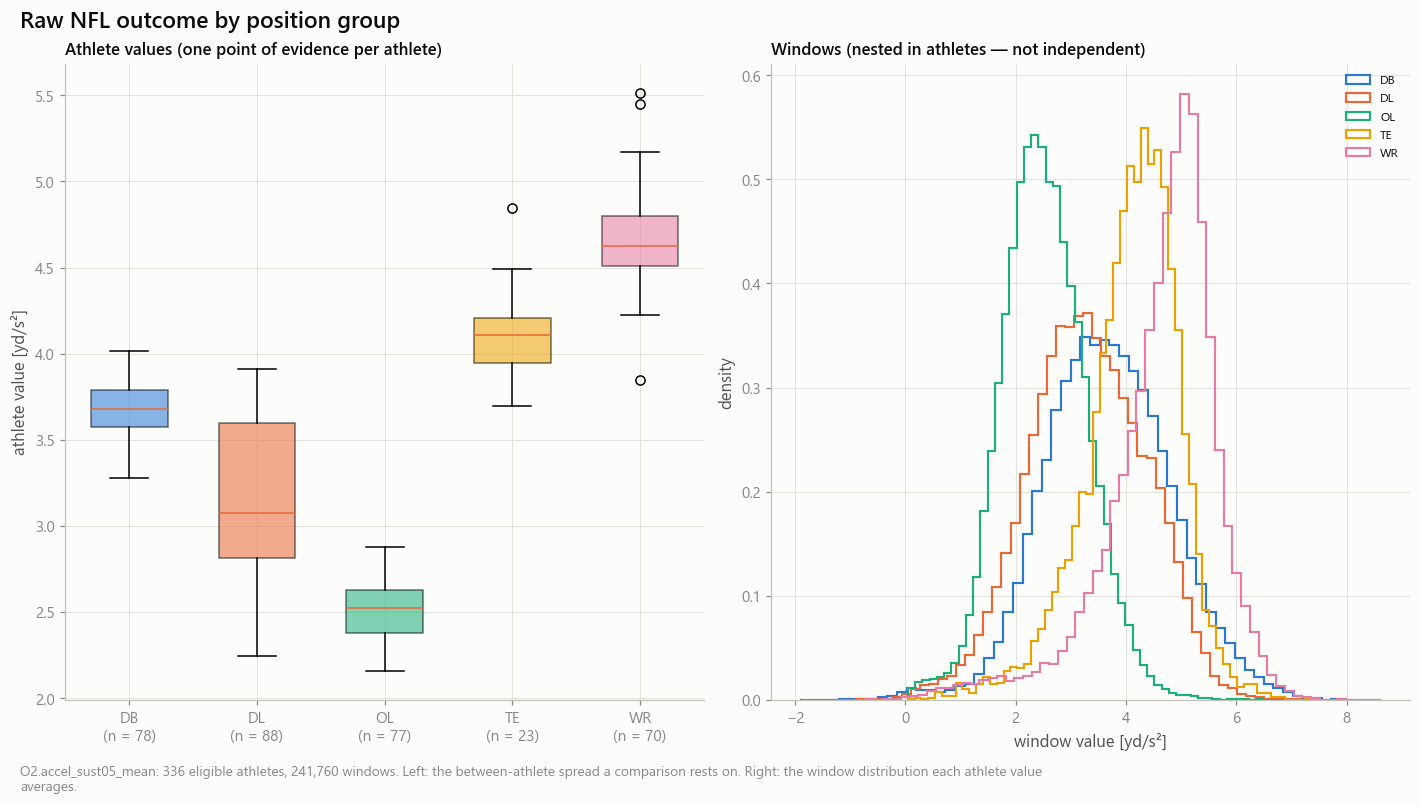

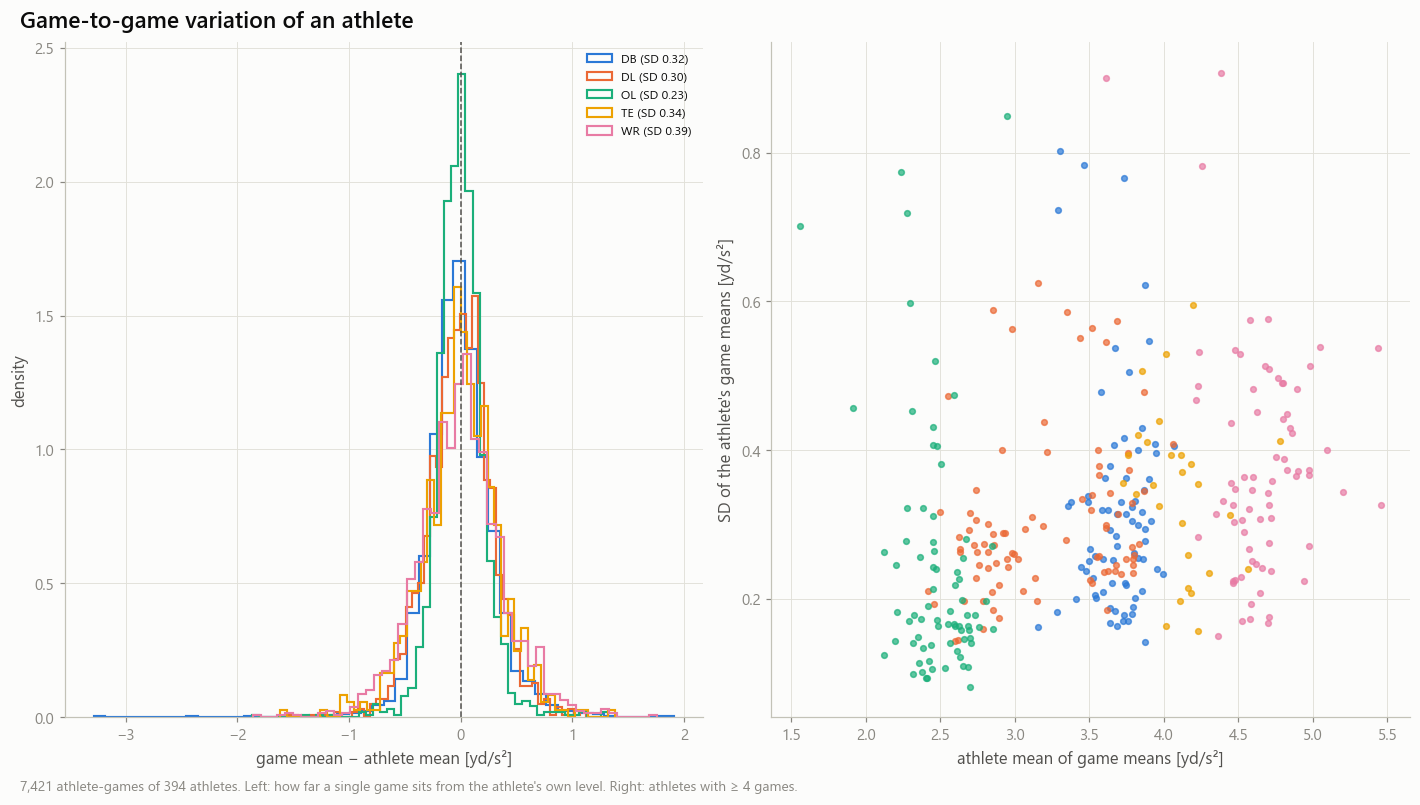

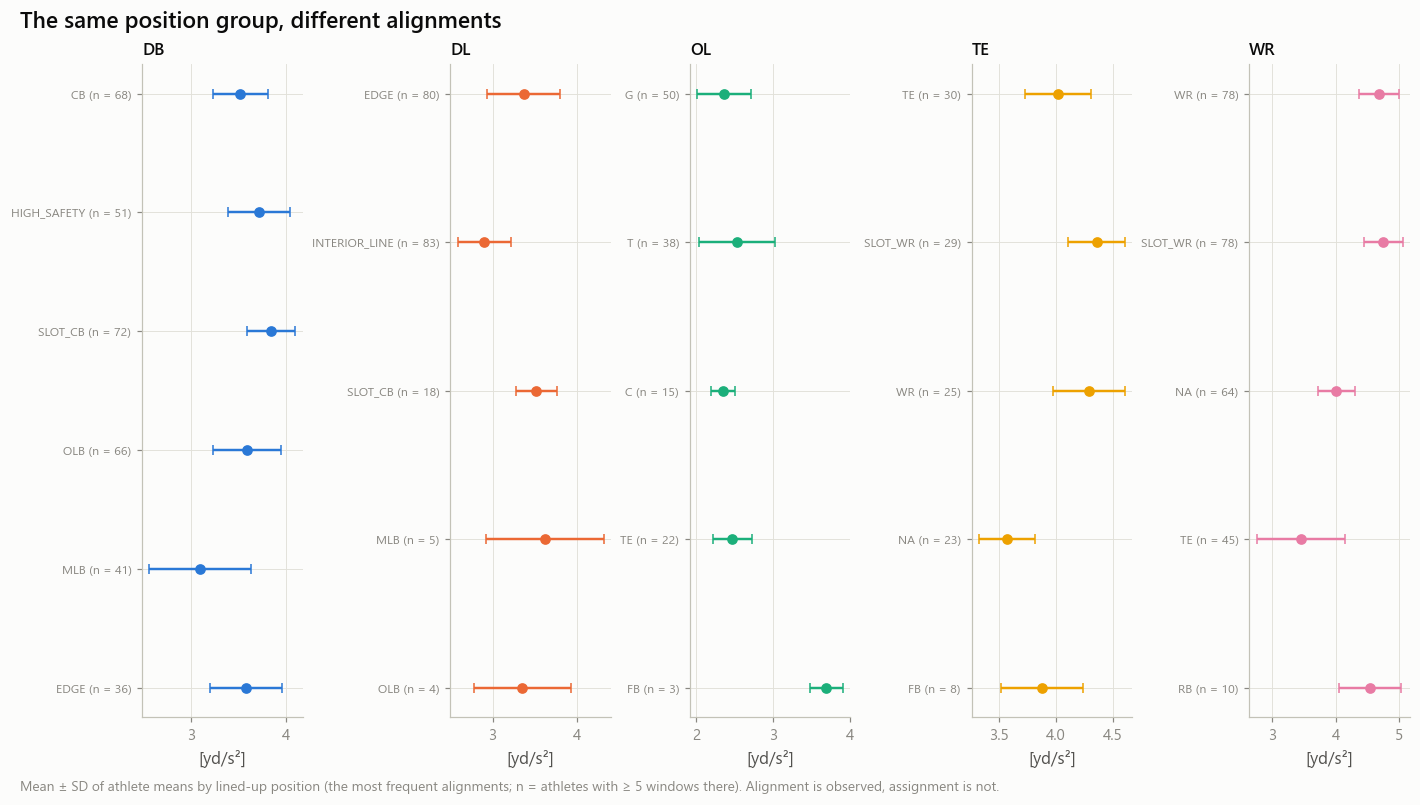

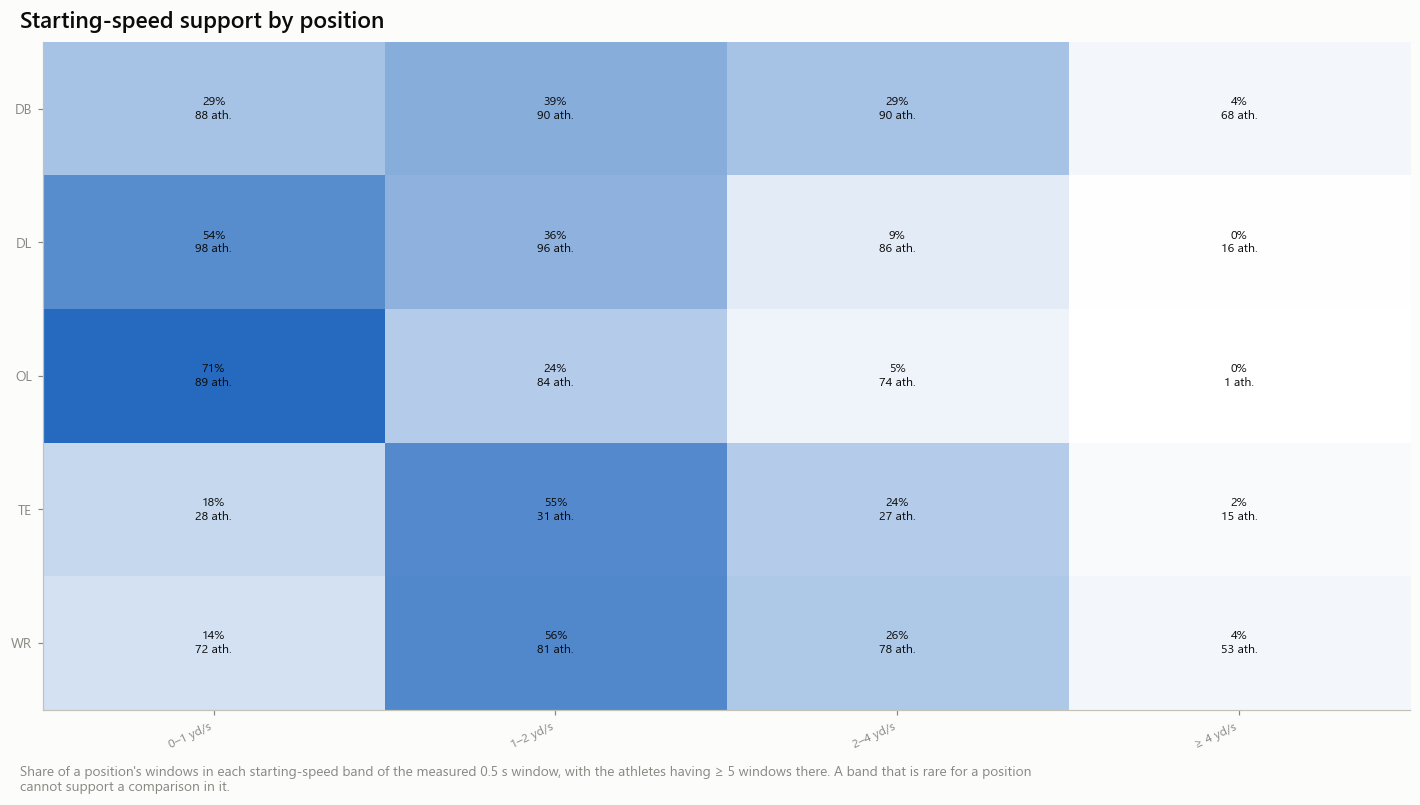

In [4]:
wf = W.frame(cc)
stage1 = store.build('07A_distribution', [co.DIST], lambda: {co.DIST.name: co.distribution_table(W, cc)}, PARAMS, [PLAYS_FILE])
dist = stage1[co.DIST.name]
display(Markdown(f'**Play measure `{W.measure}` in {U}** — limit of physical plausibility: {cc.max_accel} yd/s² (kinematics configuration)'))
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=3):
    display(dist.filter(pl.col('group_type').is_in(['position', 'cohort', 'season', 'exposure'])))

adjusted0 = co.adjusted_table(lab, ['C0'])
store.show(cf.plot_raw_distributions(adjusted0, wf, U, P), 'AM07A_01_raw_distributions', {'athletes': adjusted0}, publication=True,
           source='nfl_play_movement (05A)', n=f'{W.n_athletes} athletes')
game_means = wf.group_by('nfl_id', 'position_group', 'game_id').agg(pl.col('y').mean().alias('mean'), pl.len().alias('n')).filter(pl.col('n') >= ocfg.min_game_windows)
store.show(cf.plot_player_game_variation(game_means, U), 'AM07A_02_player_game_variation', {'athlete_games': game_means},
           source='nfl_play_movement (05A)', n=f'{game_means.height:,} athlete-games')
store.show(cf.plot_alignment_comparison(dist, U), 'AM07A_06_alignment_comparison', {'distribution': dist.filter(pl.col('group_type') == 'alignment')},
           source='nfl_context_distribution', n=f'{W.n_athletes} athletes')
store.show(cf.plot_start_speed_support(dist), 'AM07A_07_start_speed_support', {'distribution': dist.filter(pl.col('group_type') == 'start_band')},
           source='nfl_context_distribution', n=f'{W.n_windows:,} windows')

## 2. Variance decomposition

Nested layout athlete ⊃ game ⊃ window, method of moments for the unbalanced design, pooled **within** position and per position, with an athlete bootstrap. Position is reported apart (a fixed, observed label). Context factors are reported as marginal η² within position — window level, descriptive, **not additive** with the nested components. A moment estimate that comes out negative is truncated at 0 and **flagged**: the layer is then not distinguishable from the one below with these data.

15:33:51 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07A_variance] computing (never run)
15:33:53 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_variance] nfl_context_variance_decomposition: 24 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_variance_decomposition.parquet
15:33:53 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_variance] nfl_context_scale_audit: 24 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_scale_audit.parquet


scope,component,variance,share_within_position,share_total,ci_lower,ci_upper,n_athletes,truncated,note
str,str,f64,f64,f64,f64,f64,i64,bool,str
"""ALL""","""athlete""",0.0602,0.0628,0.0399,0.0504,0.0725,401,false,""""""
"""ALL""","""context:alignment""",null,0.0505,null,null,null,401,false,"""38 cells · window level, descriptive: not additive with the nested components"""
"""ALL""","""context:alignment_x_play_class""",null,0.1212,null,null,null,401,false,"""93 cells · window level, descriptive: not additive with the nested components"""
"""ALL""","""context:down""",null,0.0123,null,null,null,401,false,"""25 cells · window level, descriptive: not additive with the nested components"""
"""ALL""","""context:season""",null,0.0116,null,null,null,401,false,"""15 cells · window level, descriptive: not additive with the nested components"""
"""ALL""","""context:starting_speed_band""",null,0.0861,null,null,null,401,false,"""20 cells · window level, descriptive: not additive with the nested components · 4 bands"""
"""ALL""","""game_within_athlete""",0.0336,0.0350,0.0222,0.0306,0.0400,401,false,""""""
"""ALL""","""position""",0.5510,null,0.3650,null,null,401,false,"""position is a fixed, observed label: this share is not an athlete difference"""
"""ALL""","""window_within_game""",0.8659,0.9023,0.5729,0.8915,0.9154,401,false,""""""


**Scale audit** — between-athlete spread against the standard error of ONE athlete value at the median exposure

scope,definition,n_athletes,between_sd,p10,p90,median_windows,median_games,standard_error,snr,model_reliability,unit
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""ALL""","""C0""",336,0.2868,-0.3370,0.3941,471.0000,18.0000,0.0608,4.0347,0.9421,"""yd/s²"""
"""DB""","""C0""",78,0.1556,-0.2006,0.1899,609.5000,19.0000,0.0578,2.4886,0.8610,"""yd/s²"""
"""DL""","""C0""",88,0.4438,-0.5458,0.5683,353.5000,17.0000,0.0675,6.3180,0.9756,"""yd/s²"""
"""OL""","""C0""",77,0.1705,-0.2009,0.1897,943.0000,17.0000,0.0426,3.8360,0.9364,"""yd/s²"""
"""TE""","""C0""",23,0.2580,-0.3213,0.2646,262.0000,25.0000,0.0615,3.5137,0.9251,"""yd/s²"""
"""WR""","""C0""",70,0.2661,-0.2364,0.2998,350.5000,22.5000,0.0760,2.6452,0.8750,"""yd/s²"""
"""ALL""","""C2""",336,0.2618,-0.3212,0.3532,471.0000,18.0000,0.0577,3.9503,0.9398,"""yd/s²"""
"""DB""","""C2""",78,0.1567,-0.1902,0.1860,609.5000,19.0000,0.0566,2.5868,0.8700,"""yd/s²"""
"""DL""","""C2""",88,0.4059,-0.5172,0.5133,353.5000,17.0000,0.0657,5.8587,0.9717,"""yd/s²"""


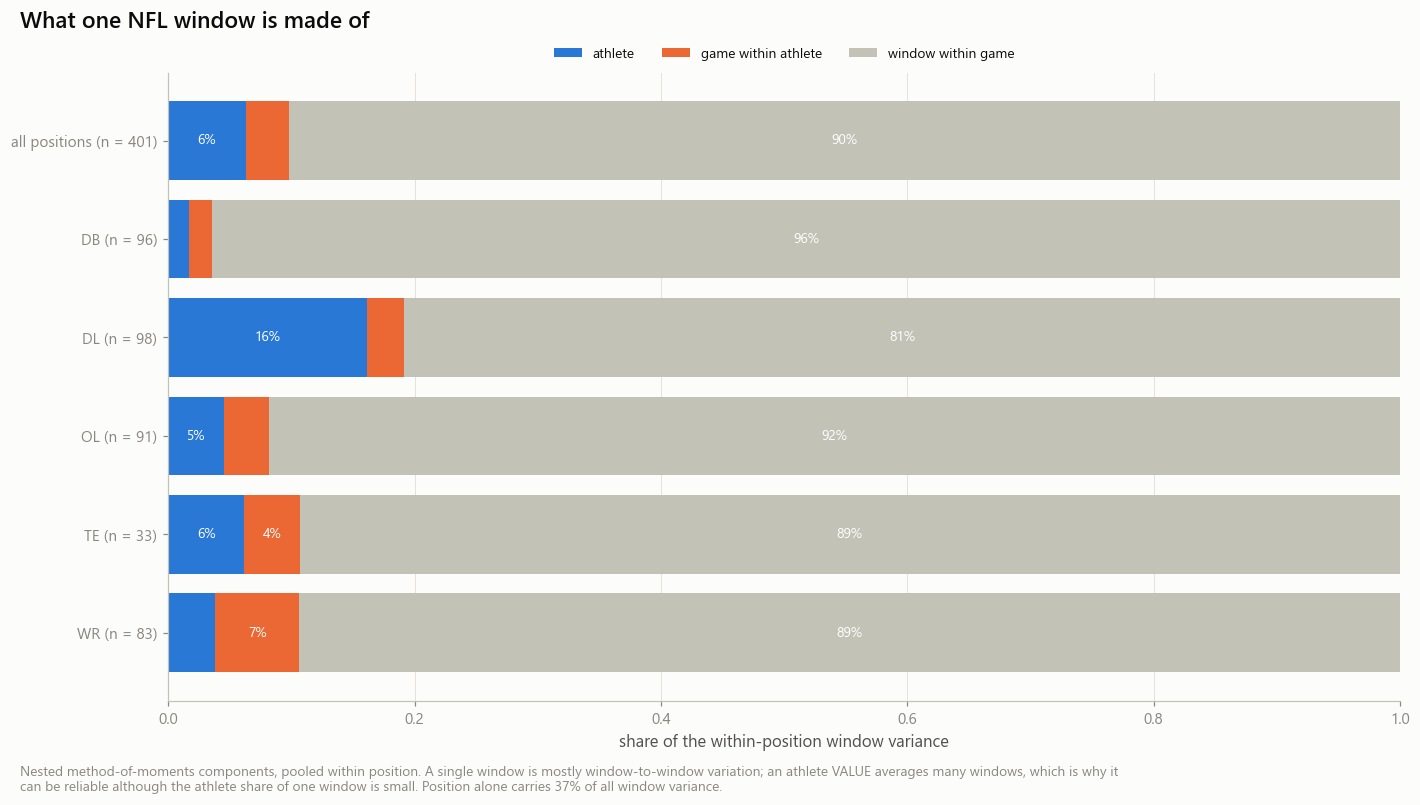

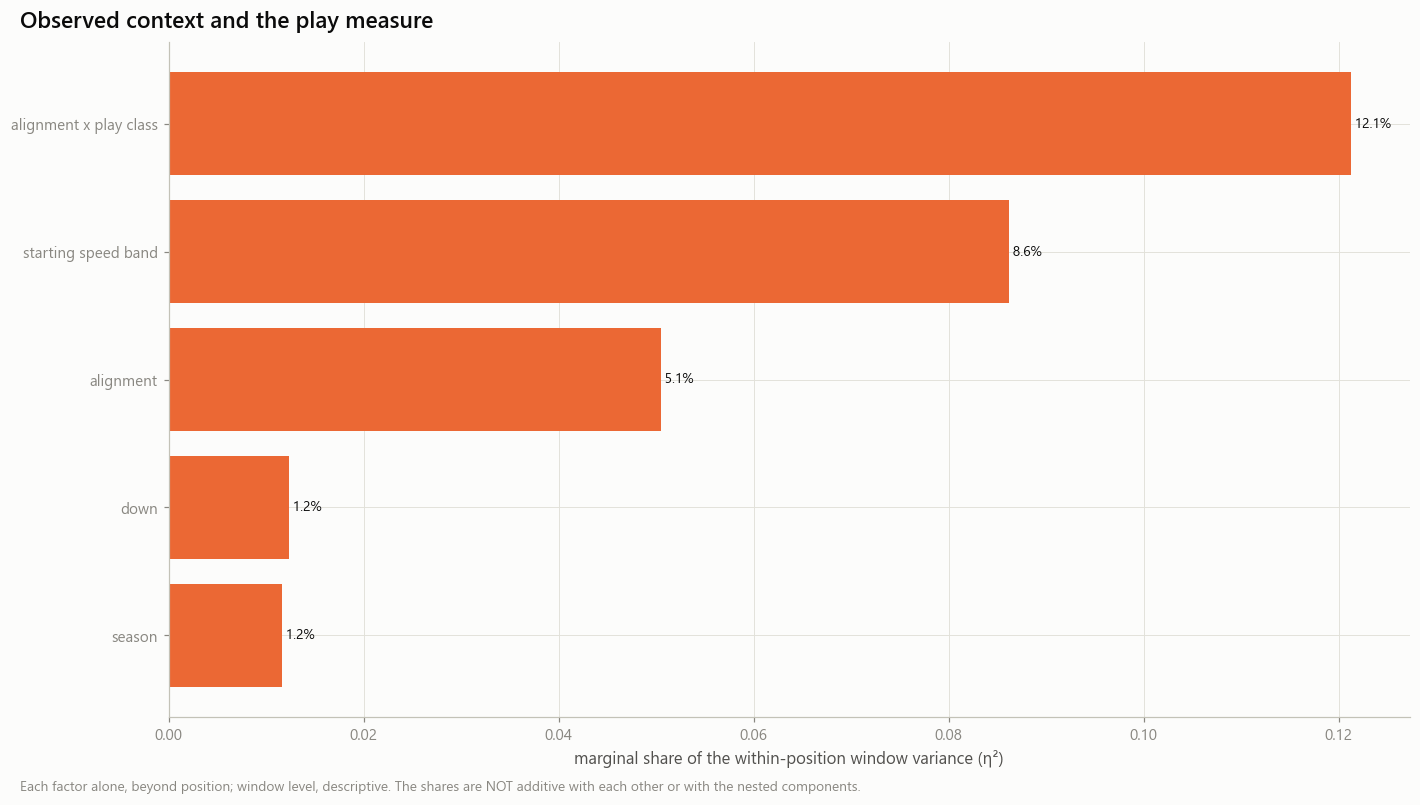

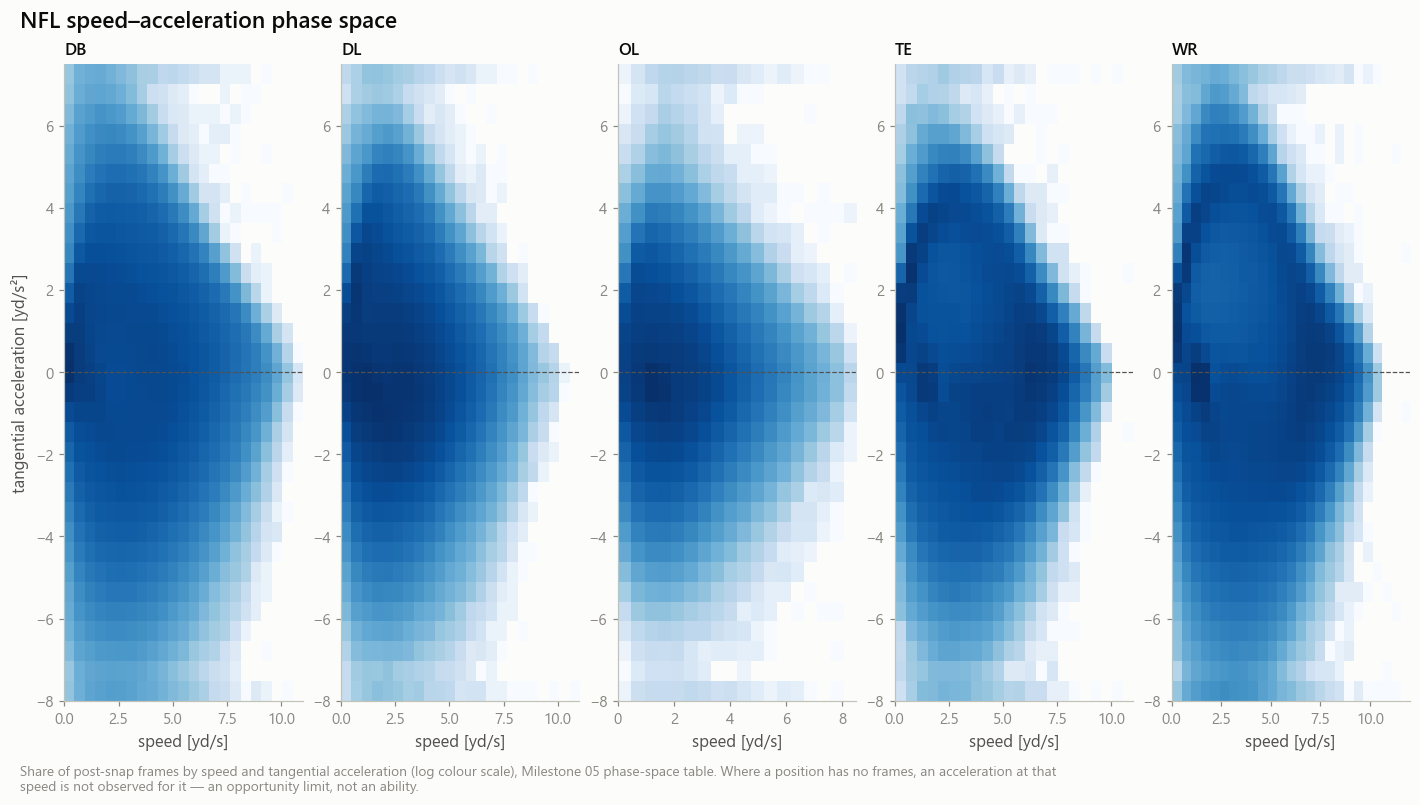

In [5]:
stage2 = store.build('07A_variance', [co.VARIANCE, co.SCALE],
                     lambda: {co.VARIANCE.name: co.variance_table(lab, controls.seed), co.SCALE.name: co.scale_table(lab, DEFINITIONS)},
                     PARAMS, [PLAYS_FILE])
variance, scale = stage2[co.VARIANCE.name], stage2[co.SCALE.name]
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4, fmt_str_lengths=120):
    display(variance.select('scope', 'component', 'variance', 'share_within_position', 'share_total', 'ci_lower', 'ci_upper', 'n_athletes', 'truncated', 'note'))
    display(Markdown('**Scale audit** — between-athlete spread against the standard error of ONE athlete value at the median exposure'))
    display(scale)
truncated = variance.filter(pl.col('truncated'))
if truncated.height:
    display(Markdown(f'**Limitation — {truncated.height} moment estimate(s) truncated at 0** (listed above): not silently replaced; read those layers as *not distinguishable here*.'))

store.show(cf.plot_variance_components(variance), 'AM07A_03_variance_components', {'variance': variance}, publication=True,
           source='nfl_context_variance_decomposition', n=f'{W.n_athletes} athletes')
store.show(cf.plot_context_association(variance), 'AM07A_04_context_association', {'variance': variance.filter(pl.col('component').str.starts_with('context:'))},
           source='nfl_context_variance_decomposition', n=f'{W.n_windows:,} windows')
phase = store.nfl.require(no.PHASE_SPACE, NB['05A'])
store.show(cf.plot_phase_space(phase), 'AM07A_05_phase_space', {'phase_space': phase}, source='nfl_phase_space (05A)', n=f'{int(phase["n_frames"].sum()):,} frames')

## 3. Context definitions and their overlap

| | Definition | What is removed | Cost |
|---|---|---|---|
| C0 | raw athlete aggregate (Milestone 05 statistic) | nothing — **reference only** | — |
| C1 | position-standardised | position mean and spread | none (monotone in C0 inside a position) |
| C2 | starting-speed-conditioned | mean of the position × starting-speed band | windows in unsupported bands are **dropped** |
| C3 | position × alignment | mean of the position × alignment cell | windows in unsupported or unlabelled cells are **dropped** |
| C4 | hierarchical | additive effects of alignment × play class, starting-speed band, season, down; then a shrunk athlete effect | model assumptions; exposure-dependent shrinkage |

The table below is **descriptive** (context parameters from all athletes). In 07B every fold recomputes them from its training athletes; in section 4 every game half uses the parameters of the other half. A definition that looks better on 35 athletes is not better: read the coverage columns first.

15:33:58 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07A_definitions] computing (never run)
15:34:01 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_definitions] nfl_context_adjusted_outcomes: 2,005 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_adjusted_outcomes.parquet
15:34:01 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_definitions] nfl_context_overlap: 5 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_overlap.parquet


definition,label,status,n_athletes_any,n_athletes_eligible,n_athlete_games,n_windows,share_windows_retained,missing_context_share,n_positions,min_position_athletes,position_counts,cells_supported,cells_total,start_speed_overlap,note
str,str,str,i64,i64,i64,i64,f64,f64,i64,i64,str,i64,i64,f64,str
"""C0""","""raw athlete aggregate (Milestone 05 statistic)""","""reference_frozen_m05""",401,336,7891,241760,1.000,null,5,23,"""DB 78 · DL 88 · OL 77 · TE 23 · WR 70""",null,null,null,""""""
"""C1""","""position-standardised athlete value""","""exploratory""",401,336,7891,241760,1.000,null,5,23,"""DB 78 · DL 88 · OL 77 · TE 23 · WR 70""",null,null,null,""""""
"""C2""","""starting-speed-conditioned (position × starting-speed band)""","""exploratory""",401,336,7891,241760,1.000,0.000,5,23,"""DB 78 · DL 88 · OL 77 · TE 23 · WR 70""",20,20,1.000,"""windows in unsupported cells are DROPPED, not left unadjusted"""
"""C3""","""position × alignment conditioned""","""exploratory""",400,334,7851,239402,0.990,0.009,5,22,"""DB 78 · DL 88 · OL 77 · TE 22 · WR 69""",27,38,null,"""windows in unsupported cells are DROPPED, not left unadjusted"""
"""C4""","""hierarchical context-adjusted athlete effect (shrunk)""","""exploratory""",401,336,7891,241760,1.000,0.000,5,23,"""DB 78 · DL 88 · OL 77 · TE 23 · WR 70""",61,93,1.000,"""backfitting converged = False, 30 iteration(s)"""


**C4 fit** — backfitting converged: `False` after 30 iteration(s) (last change 2.60e-04); levels adjusted per factor [61, 20, 15, 25] of [255, 24, 15, 25]; athlete variance truncated: `False`; median shrinkage factor 0.787

**Limitation:** the backfitting did not converge within the iteration budget — C4 values are reported but must be read with that caveat.

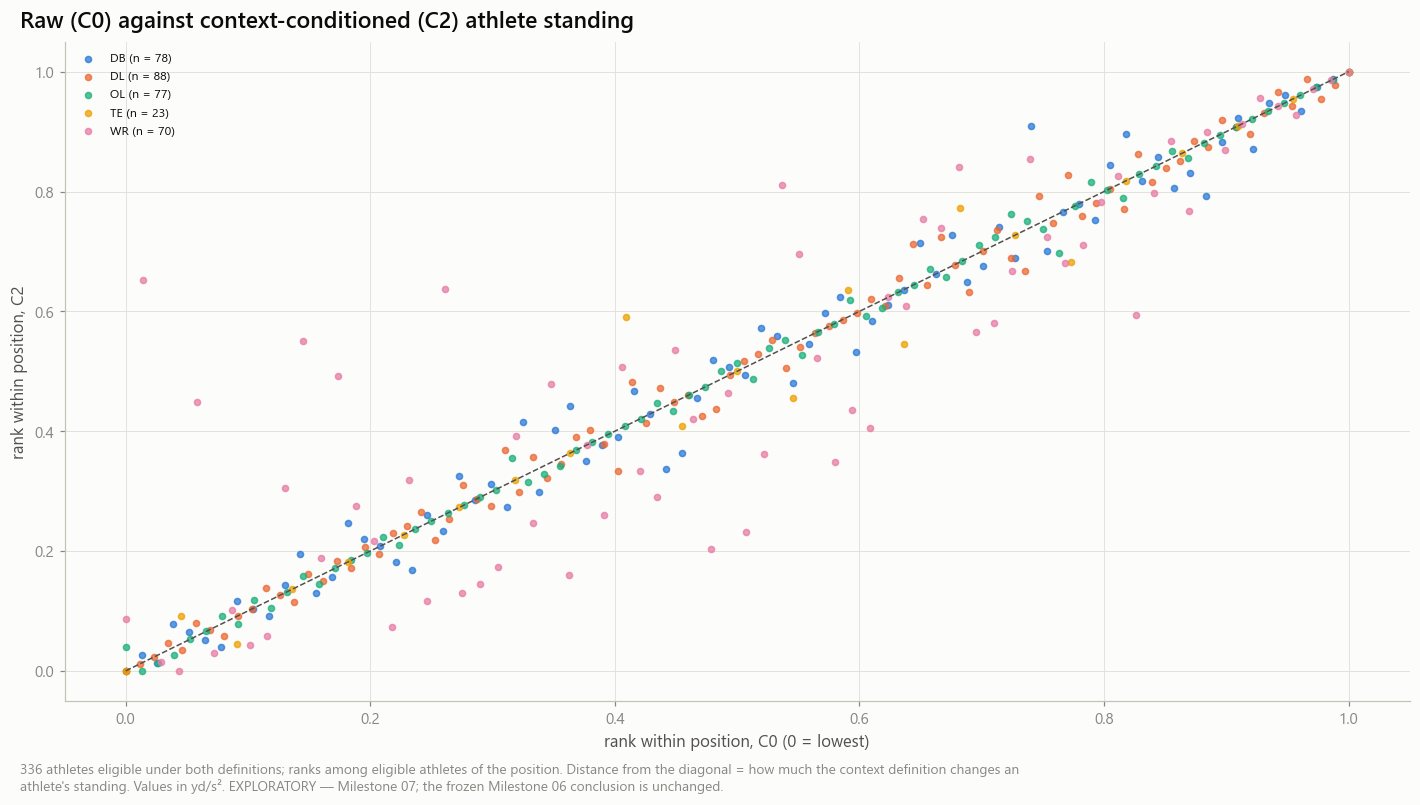

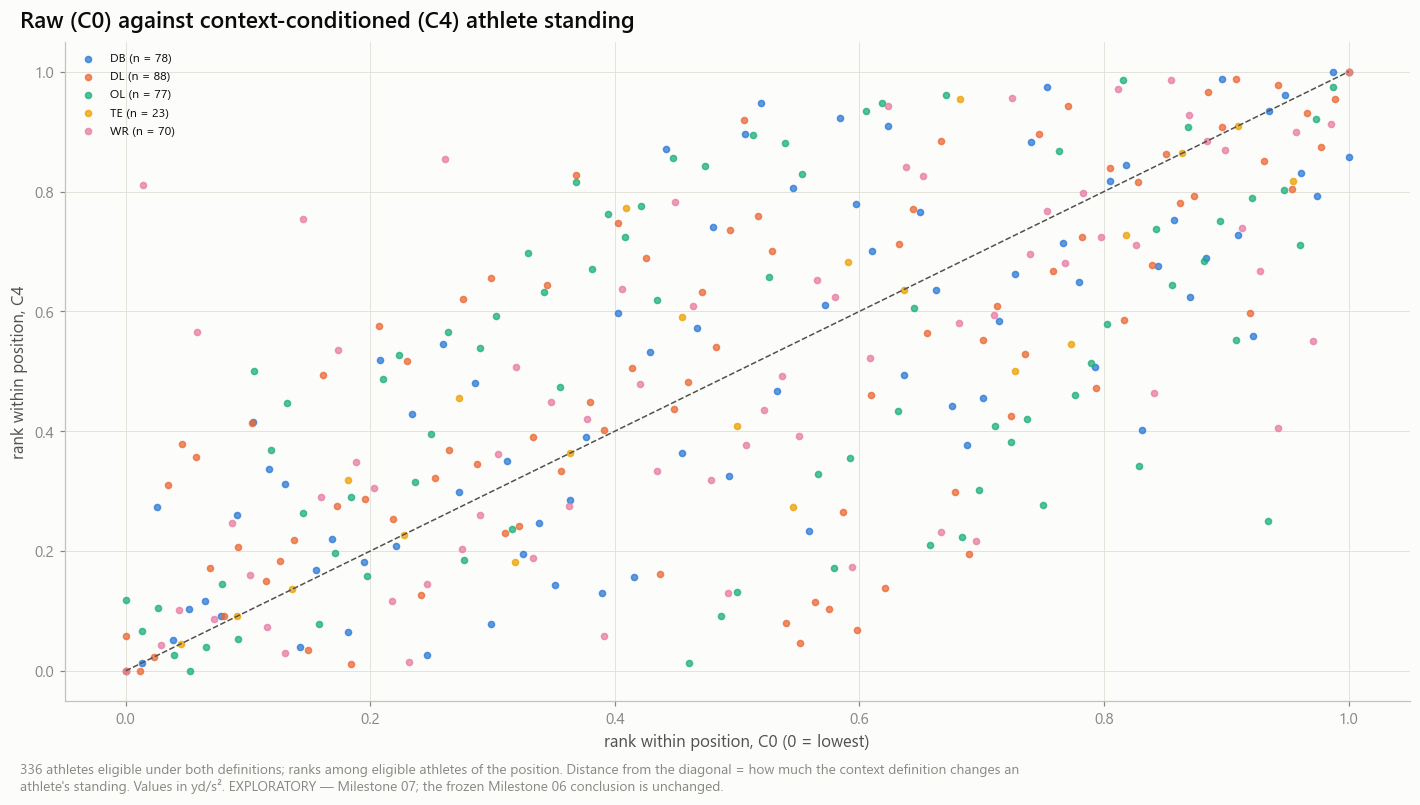

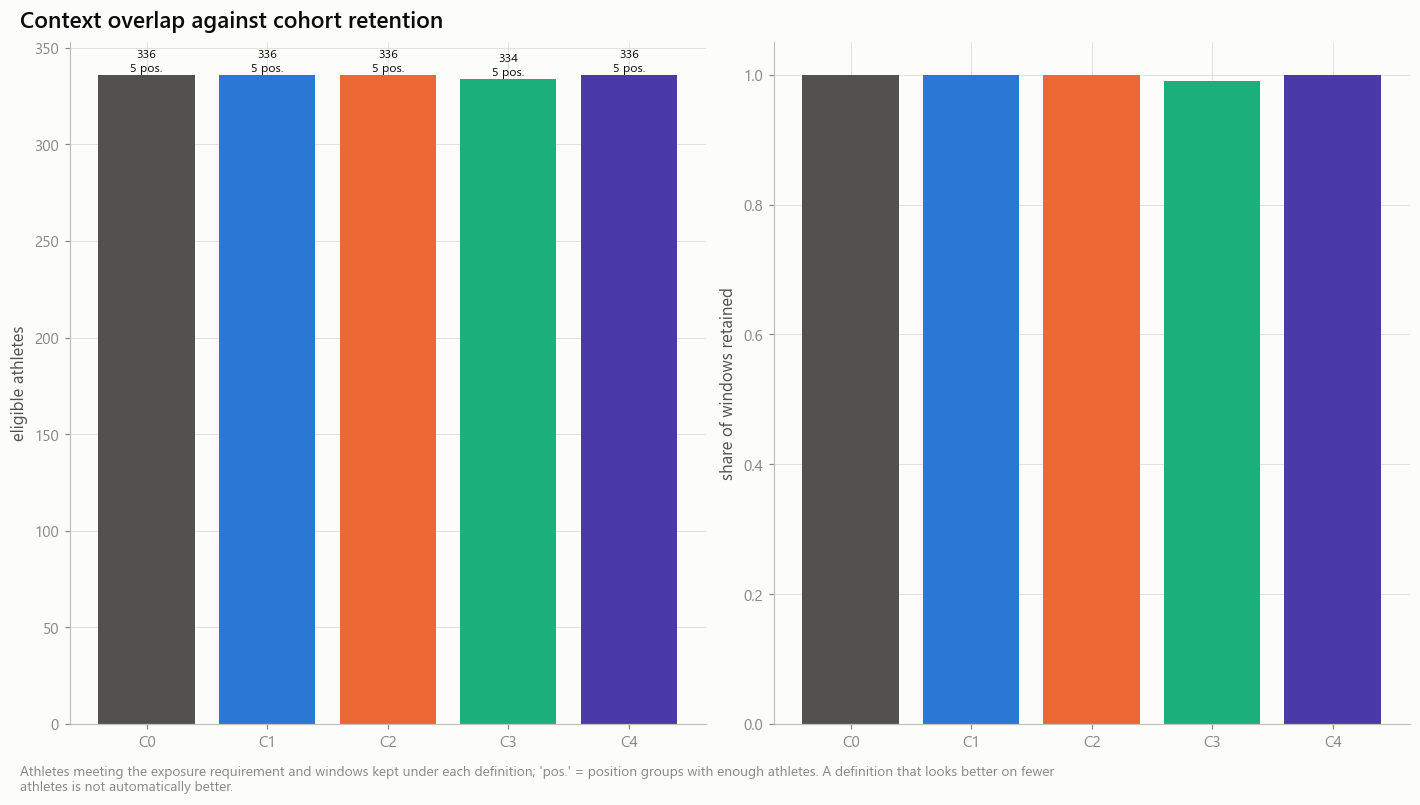

In [6]:
stage3 = store.build('07A_definitions', [co.ADJUSTED, co.OVERLAP],
                     lambda: {co.ADJUSTED.name: co.adjusted_table(lab, DEFINITIONS), co.OVERLAP.name: co.overlap_table(lab, DEFINITIONS)},
                     PARAMS, [PLAYS_FILE])
adjusted, overlap = stage3[co.ADJUSTED.name], stage3[co.OVERLAP.name]
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=3, fmt_str_lengths=160):
    display(overlap)
AVAILABLE = overlap.filter(pl.col('status') != 'unavailable')['definition'].to_list()
c4_info = (lab.values('C4'), lab.last_info)[1] if 'C4' in AVAILABLE else {}
if c4_info:
    display(Markdown(f'**C4 fit** — backfitting converged: `{c4_info.get("converged")}` after {c4_info.get("iterations")} iteration(s) (last change {c4_info.get("last_change"):.2e}); '
                     f'levels adjusted per factor {c4_info.get("levels_adjusted")} of {c4_info.get("levels_total")}; athlete variance truncated: `{c4_info.get("truncated_athlete")}`; '
                     f'median shrinkage factor {c4_info.get("median_shrink"):.3f}'))
    if not c4_info.get('converged'):
        display(Markdown('**Limitation:** the backfitting did not converge within the iteration budget — C4 values are reported but must be read with that caveat.'))

for b in [d for d in ('C2', 'C4') if d in AVAILABLE]:
    store.show(cf.plot_raw_vs_adjusted(adjusted, b, U), f'AM07A_08_raw_vs_{b}', {'adjusted': adjusted.filter(pl.col('definition').is_in(['C0', b]))},
               publication=(b == 'C4'), source='nfl_context_adjusted_outcomes', n=f'{W.n_athletes} athletes')
store.show(cf.plot_overlap_retention(overlap), 'AM07A_09_overlap_retention', {'overlap': overlap}, source='nfl_context_overlap', n=f'{W.n_athletes} athletes')

## 4. Out-of-game reliability (cross-fitted)

Halves are sets of whole games. The value of one half is adjusted with context parameters estimated on the **other** half, so the games an athlete is evaluated on never inform the adjustment applied to them. Estimate: pooled within-position correlation → Spearman–Brown, mean over random splits; interval: athlete bootstrap of the odd / even split. Then: how much NFL history a value needs (first N games / windows against later games).

Work: `len(DEFINITIONS) × (N_GAME_SPLITS + 1)` passes over the window table — progress and a run-time estimate are printed.

15:34:05 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:07A_reliability] computing (never run)


[07A reliability] 255 iteration(s) planned
[07A reliability] 10/255 · elapsed 0.2 s · about 4.4 s left · C0
[07A reliability] 20/255 · elapsed 0.3 s · about 4.0 s left · C0
[07A reliability] 30/255 · elapsed 0.5 s · about 3.9 s left · C0
[07A reliability] 40/255 · elapsed 0.7 s · about 3.8 s left · C0
[07A reliability] 50/255 · elapsed 0.9 s · about 3.7 s left · C0
[07A reliability] 60/255 · elapsed 1.7 s · about 5.4 s left · C1
[07A reliability] 70/255 · elapsed 2.0 s · about 5.2 s left · C1
[07A reliability] 80/255 · elapsed 2.2 s · about 4.8 s left · C1
[07A reliability] 90/255 · elapsed 2.4 s · about 4.4 s left · C1
[07A reliability] 100/255 · elapsed 2.6 s · about 4.0 s left · C1
[07A reliability] 110/255 · elapsed 3.5 s · about 4.6 s left · C2
[07A reliability] 120/255 · elapsed 3.9 s · about 4.4 s left · C2
[07A reliability] 130/255 · elapsed 4.3 s · about 4.2 s left · C2
[07A reliability] 140/255 · elapsed 4.8 s · about 3.9 s left · C2
[07A reliability] 150/255 · elapsed 5.2 s 

15:36:32 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_reliability] nfl_context_outcome_reliability: 100 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_outcome_reliability.parquet
15:36:32 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07A_reliability] nfl_context_coverage_tradeoff: 5 rows → warehouse/gold/advanced_movement/context_transfer/nfl_context_coverage_tradeoff.parquet


definition,method,scope,n_athletes,r_half,reliability,ci_lower,ci_upper,icc,split_sd,n_splits,fit_isolation
str,str,str,i64,f64,f64,f64,f64,f64,f64,i64,str
"""C0""","""random_game_halves_crossfit""","""ALL""",333,0.856,0.922,0.914,0.956,0.875,0.009,50,"""no parameter"""
"""C0""","""random_game_halves_crossfit""","""DB""",76,0.657,0.792,0.757,0.911,0.729,0.038,50,"""no parameter"""
"""C0""","""random_game_halves_crossfit""","""DL""",88,0.929,0.963,0.952,0.979,0.932,0.006,50,"""no parameter"""
"""C0""","""random_game_halves_crossfit""","""OL""",76,0.686,0.811,0.763,0.948,0.669,0.065,50,"""no parameter"""
"""C0""","""random_game_halves_crossfit""","""TE""",23,0.880,0.936,0.863,0.980,0.894,0.020,50,"""no parameter"""
"""C0""","""random_game_halves_crossfit""","""WR""",70,0.815,0.898,0.907,0.962,0.870,0.024,50,"""no parameter"""
"""C1""","""random_game_halves_crossfit""","""ALL""",333,0.793,0.884,0.870,0.935,0.813,0.017,50,"""parameters from the other game half (cross-fitted)"""
"""C1""","""random_game_halves_crossfit""","""DB""",76,0.655,0.790,0.756,0.905,0.731,0.034,50,"""parameters from the other game half (cross-fitted)"""
"""C1""","""random_game_halves_crossfit""","""DL""",88,0.932,0.965,0.951,0.979,0.922,0.006,50,"""parameters from the other game half (cross-fitted)"""


**Coverage trade-off** (`feasible` applies heuristic reference lines; the reading is the analyst's)

definition,label,complexity,status,n_athletes_eligible,share_athletes_retained,n_positions,reliability,ci_lower,ci_upper,min_position_reliability,spearman_with_c0,feasible,reason
str,str,i64,str,i64,f64,i64,f64,f64,f64,f64,f64,bool,str
"""C0""","""raw athlete aggregate (Milestone 05 statistic)""",0,"""reference_frozen_m05""",336,1.000,5,0.922,0.914,0.956,0.792,1.000,true,""""""
"""C1""","""position-standardised athlete value""",1,"""exploratory""",336,1.000,5,0.884,0.870,0.935,0.790,0.982,true,""""""
"""C2""","""starting-speed-conditioned (position × starting-speed band)""",2,"""exploratory""",336,1.000,5,0.915,0.897,0.952,0.786,0.973,true,""""""
"""C3""","""position × alignment conditioned""",3,"""exploratory""",334,0.994,5,0.819,0.773,0.884,0.636,0.724,true,""""""
"""C4""","""hierarchical context-adjusted athlete effect (shrunk)""",4,"""exploratory""",336,1.000,5,0.829,0.823,0.887,0.788,0.641,true,""""""


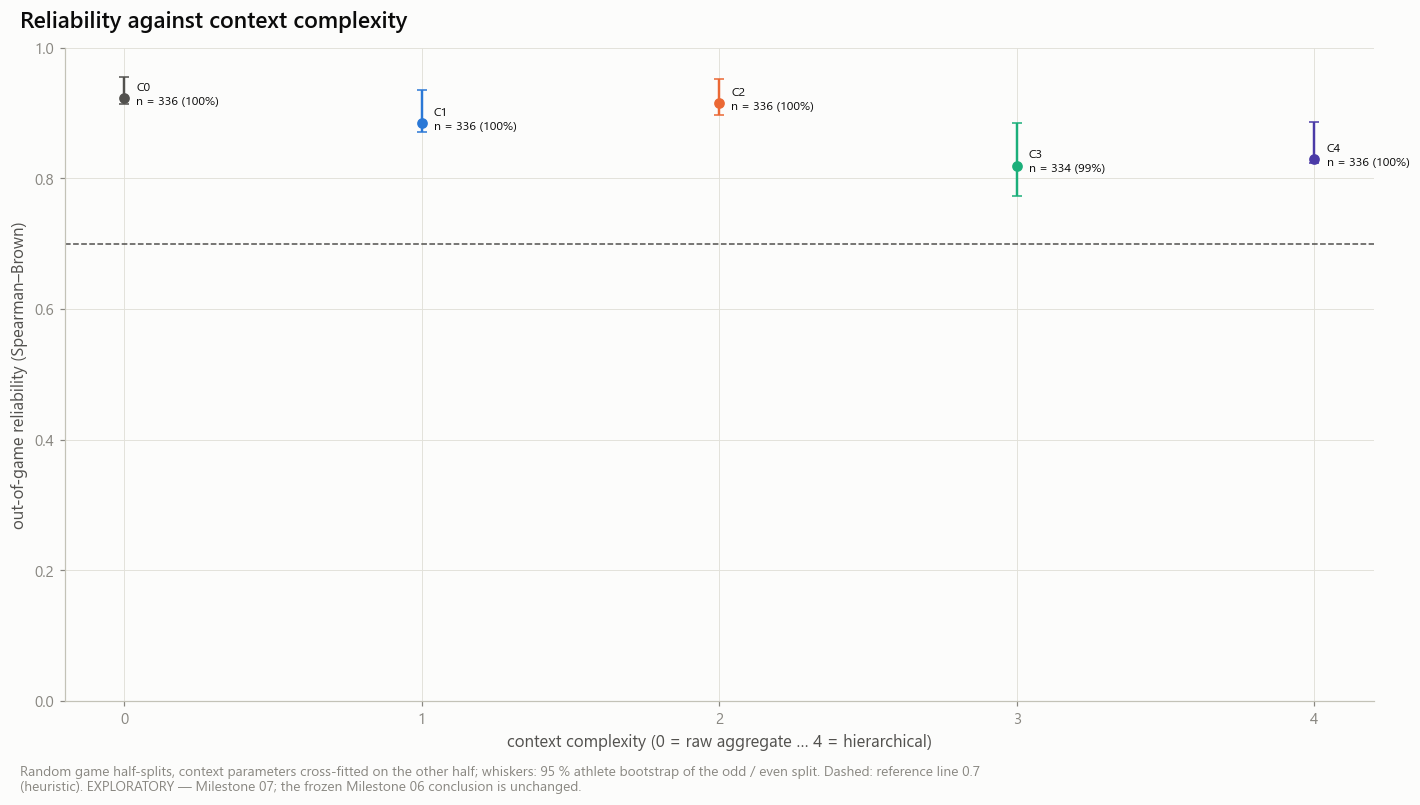

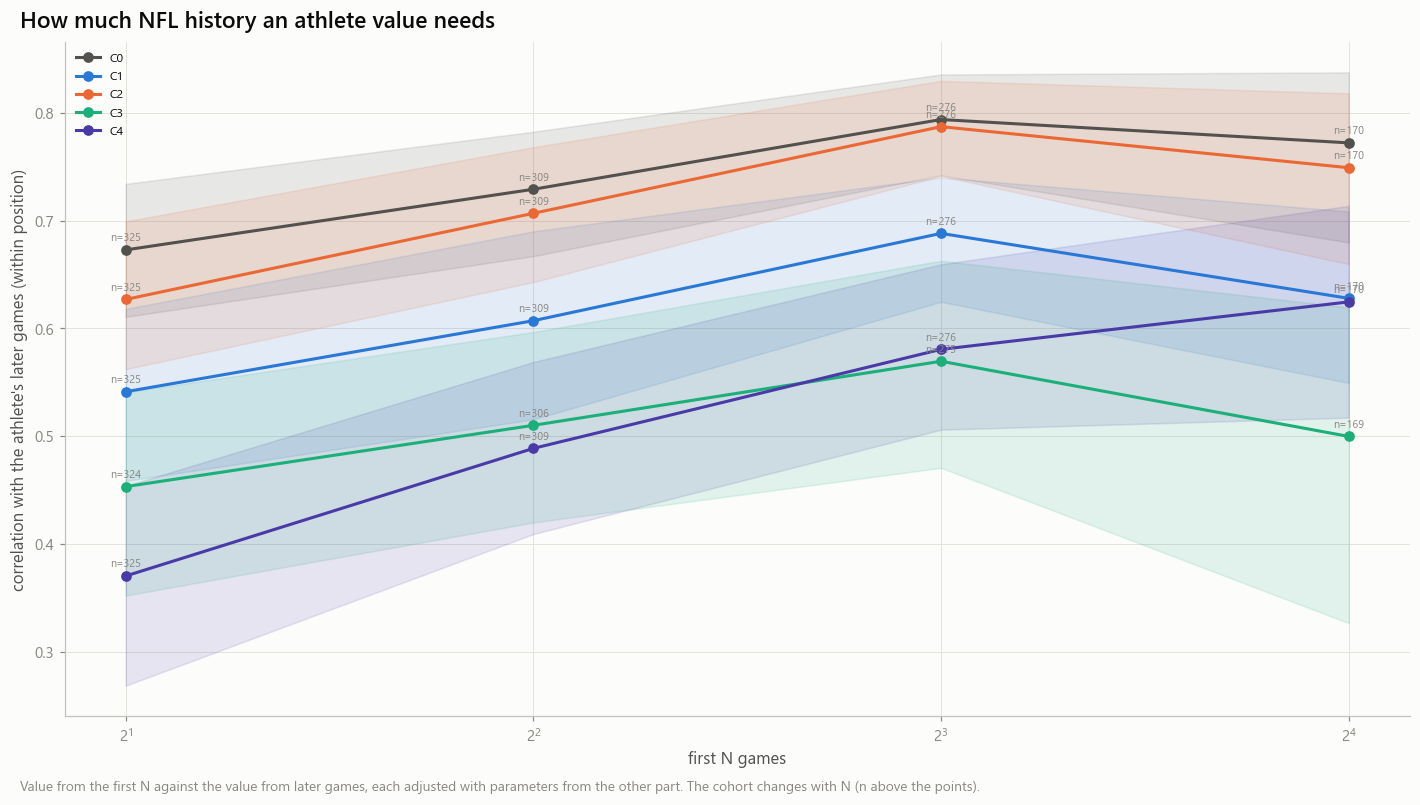

nfl_id,position_group,value_C0,rank_C0,n_windows,value_C4,rank_C4,rank_shift
i64,str,f64,f64,i64,f64,f64,f64
58413,"""WR""",4.221908,0.014493,76,4.767665,0.811594,0.797101
55971,"""OL""",2.709773,0.934211,691,2.463002,0.25,-0.684211
57256,"""WR""",4.461899,0.144928,65,4.758363,0.753623,0.608696
58308,"""WR""",4.522429,0.26087,404,4.793181,0.855072,0.594203
56248,"""WR""",5.093238,0.942029,205,4.685046,0.405797,-0.536232
55905,"""DL""",3.33761,0.597701,176,3.133636,0.068966,-0.528736
58440,"""WR""",4.332459,0.057971,292,4.725548,0.565217,0.507246
58329,"""DL""",3.197371,0.551724,164,3.124275,0.045977,-0.505747


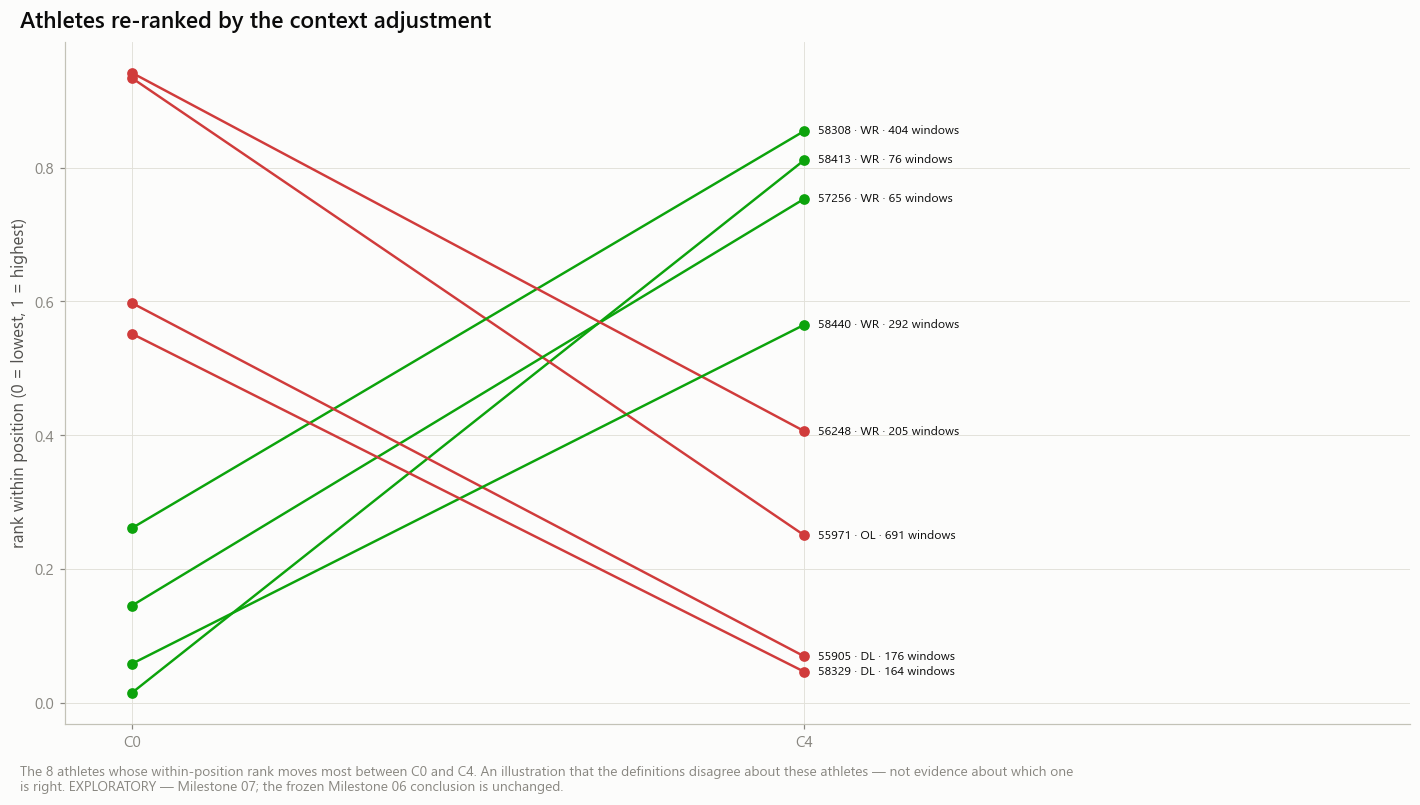

In [7]:
def build_reliability():
    rel = cr.reliability_table(lab, AVAILABLE, controls.seed)
    exp = cr.exposure_table(lab, AVAILABLE, controls.seed)
    both = pl.concat([rel, exp])
    return {cr.RELIABILITY.name: both, cr.TRADEOFF.name: cr.tradeoff_table(lab, overlap, rel, AVAILABLE)}

stage4 = store.build('07A_reliability', [cr.RELIABILITY, cr.TRADEOFF], build_reliability, {**PARAMS, 'available': AVAILABLE}, [PLAYS_FILE])
reliability, tradeoff = stage4[cr.RELIABILITY.name], stage4[cr.TRADEOFF.name]
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=3, fmt_str_lengths=160):
    display(reliability.filter(pl.col('method') == 'random_game_halves_crossfit'))
    display(Markdown('**Coverage trade-off** (`feasible` applies heuristic reference lines; the reading is the analyst\'s)'))
    display(tradeoff)

store.show(cf.plot_reliability_complexity(tradeoff, cc.ref_reliability), 'AM07A_10_reliability_vs_complexity', {'tradeoff': tradeoff}, publication=True,
           source='nfl_context_coverage_tradeoff', n=f'{W.n_athletes} athletes')
store.show(cf.plot_reliability_exposure(reliability, 'first_games'), 'AM07A_11_reliability_vs_games', {'reliability': reliability.filter(pl.col('method').str.starts_with('first_'))},
           source='nfl_context_outcome_reliability', n='athletes with enough later games (see points)')
a_def, b_def = RANK_SHIFT_PAIR if RANK_SHIFT_PAIR[1] in AVAILABLE else ('C0', AVAILABLE[-1])
examples = co.rank_shift_examples(adjusted, a_def, b_def, cc.rank_shift_k)
display(examples)
store.show(cf.plot_rank_shift(examples, a_def, b_def), 'AM07A_12_rank_shift_examples', {'examples': examples}, source='nfl_context_adjusted_outcomes',
           n=f'{examples.height} athletes (illustration)')

## 5. Exploratory registry, gate 07A and reading

The registry written here is **exploratory** and lives beside — never in place of — `nfl_movement_targets_v1.json`. Gate 07A passes when the question was answered validly (definitions documented, athlete variation retained, reliability evaluated across games, coverage and overlap reported). It does **not** require that an adjusted definition beats the raw one; if none meets the reference lines, nothing is promoted and 07B uses the context definitions only as labelled exploratory outcomes.

What a context adjustment can and cannot say: it separates *observed game movement* from the part explained by *observed* position, alignment, play class, starting speed, season and down. Movement **opportunity** and **assignment** are only partly visible through those labels; **athletic capability** is not observed at all; **football performance** is a different quantity again.

In [8]:
gate = cr.gate_07a(overlap, variance, scale, reliability, tradeoff, cc)
with pl.Config(tbl_rows=-1, fmt_str_lengths=400):
    display(gate)
GATE_07A = 'PASS' if gate['passed'].all() else 'FAIL'
PROMOTABLE = tradeoff.filter(pl.col('feasible') & (pl.col('status') == 'exploratory'))['definition'].to_list()

text = cr.conclusions_07a(variance, tradeoff, scale, P, U)
display(Markdown(text))
display(Markdown(f'**Gate 07A: {GATE_07A}** · exploratory definitions meeting the reference lines: `{PROMOTABLE or "none"}`'))

if controls.save_tables:
    reg = co.target_registry(lab, overlap, reliability, registry_doc['version_hash'], AVAILABLE)
    store.write_json('nfl_context_target_registry', {**reg, 'gate_07a': GATE_07A, 'promotable': PROMOTABLE})
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    (store.tables_dir / 'nfl_context_conclusions.md').write_text(text, encoding='utf-8')
    store.write_json('context_decomposition_manifest', {
        'notebook': '07a_nfl_outcome_context_decomposition.ipynb', 'status': 'executed', 'experiment_version': EXPERIMENT_VERSION, 'seed': controls.seed,
        'frozen_targets_version_hash': registry_doc['version_hash'], 'outcome_id': P, 'unit': U, 'definitions_available': AVAILABLE,
        'n_athletes': W.n_athletes, 'n_athlete_games': int(W.ag_athlete.size), 'n_windows': W.n_windows, 'config': cc.params(),
        'validation': dict(zip(validation['check'], validation['status'])), 'gate_07a': GATE_07A, 'promotable': PROMOTABLE,
        'tables': [c.name for c in (co.DIST, co.VARIANCE, co.SCALE, co.ADJUSTED, co.OVERLAP, cr.RELIABILITY, cr.TRADEOFF)], 'written_by': utc_now()})
cr.assert_gate(gate, '07A')

criterion,passed,detail
str,bool,str
"""definitions_documented""",true,"""5 definition(s) computed; unavailable: []"""
"""athlete_variation_retained""",true,"""athlete share of the within-position window variance 0.0627619994785546; between-athlete SD / standard error 4.03467396914781 (reference 2.0)"""
"""reliability_evaluated_across_games""",true,"""C0 0.922 (n = 333); C1 0.884 (n = 333); C2 0.915 (n = 333); C3 0.819 (n = 331); C4 0.829 (n = 333)"""
"""coverage_documented""",true,"""C0 336 athletes; C1 336 athletes; C2 336 athletes; C3 334 athletes; C4 336 athletes"""
"""opportunity_overlap_adequate""",true,"""every definition covers ≥ 3 position groups"""
"""promotion_candidates (informative)""",true,"""exploratory definitions meeting the reference lines: ['C1', 'C2', 'C3', 'C4']"""


### What the tables show (`O2.accel_sust05_mean`, yd/s²)

- **Position** carries 0.365 of all window variance — a fixed label, not an athlete difference.
- Within position, **stable athlete differences**: 0.063 [0.050, 0.072]
- Within position, **game-to-game variation of an athlete**: 0.035 [0.031, 0.040]
- Within position, **window-to-window variation inside a game**: 0.902 [0.892, 0.915]
- Marginal share of `alignment` within position: 0.051 (window level, not additive).
- Marginal share of `alignment_x_play_class` within position: 0.121 (window level, not additive).
- Marginal share of `down` within position: 0.012 (window level, not additive).
- Marginal share of `season` within position: 0.012 (window level, not additive).
- Marginal share of `starting_speed_band` within position: 0.086 (window level, not additive).
- Scale: between-athlete SD 0.287 yd/s² within position; standard error of one athlete's value 0.061 yd/s² at the median exposure (ratio 4.03).

| Definition | Athletes | Kept | Reliability [95 %] | ρ with C0 | Feasible |
|---|---|---|---|---|---|
| C0 — raw athlete aggregate (Milestone 05 statistic) | 336 | 1.00 | 0.922 [0.914, 0.956] | 1.000 | yes |
| C1 — position-standardised athlete value | 336 | 1.00 | 0.884 [0.870, 0.935] | 0.982 | yes |
| C2 — starting-speed-conditioned (position × starting-speed band) | 336 | 1.00 | 0.915 [0.897, 0.952] | 0.973 | yes |
| C3 — position × alignment conditioned | 334 | 0.99 | 0.819 [0.773, 0.884] | 0.724 | yes |
| C4 — hierarchical context-adjusted athlete effect (shrunk) | 336 | 1.00 | 0.829 [0.823, 0.887] | 0.641 | yes |

Limits: an adjustment removes what OBSERVED labels explain (alignment, play class, starting speed, season, down). Assignment, opponent and scheme are unobserved; role is partly chosen because of ability. A context-adjusted value is still observed movement — not athletic capability, and not football performance. Every C1–C4 definition is EXPLORATORY.

**Gate 07A: PASS** · exploratory definitions meeting the reference lines: `['C1', 'C2', 'C3', 'C4']`

### What to send back

The validation table; the variance and scale tables (section 2) with any truncation note; the overlap table and the C4 fit line (section 3); the reliability and trade-off tables (section 4); the gate table and the reading (section 5); figures `AM07A_03`, `AM07A_08_raw_vs_C4`, `AM07A_10`; any traceback.

**Next:** `07b_physics_aligned_transfer_hypotheses.ipynb` (same `RUN_MODE`).